In [3]:
import numpy as np
import matplotlib.pyplot as plt
import imageio
import pandas as pd
from glob import iglob
import sklearn.datasets
from sklearn.decomposition import PCA

%run "C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Algebra_lineal_para_Machine_Learning/graficarVectores.ipynb"
%run "C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Algebra_lineal_para_Machine_Learning/graficarMatriz.ipynb"

In [2]:
np.random.seed(42)

x = 3*np.random.rand(200)
y = 20*x + 2*np.random.randn(200)

x = x.reshape(200,1)
y = y.reshape(200,1)

print(x)
print(y)

xy = np.hstack([x, y])
print(xy.shape)

[[1.12362036]
 [2.85214292]
 [2.19598183]
 [1.79597545]
 [0.46805592]
 [0.46798356]
 [0.17425084]
 [2.59852844]
 [1.80334504]
 [2.12421773]
 [0.06175348]
 [2.90972956]
 [2.49732792]
 [0.63701733]
 [0.5454749 ]
 [0.55021353]
 [0.91272673]
 [1.57426929]
 [1.29583506]
 [0.87368742]
 [1.83555868]
 [0.41848158]
 [0.87643395]
 [1.09908553]
 [1.36820995]
 [2.35552788]
 [0.59902135]
 [1.54270332]
 [1.77724371]
 [0.13935124]
 [1.82263456]
 [0.51157237]
 [0.19515478]
 [2.84665661]
 [2.8968961 ]
 [2.42519204]
 [0.91384131]
 [0.29301634]
 [2.05269908]
 [1.32045748]
 [0.3661147 ]
 [1.48553073]
 [0.10316556]
 [2.72796121]
 [0.77633994]
 [1.98756685]
 [0.93513323]
 [1.56020406]
 [1.64013084]
 [0.55456337]
 [2.90875388]
 [2.32539847]
 [2.81849682]
 [2.68448205]
 [1.79369994]
 [2.76562271]
 [0.26547751]
 [0.58794859]
 [0.13568187]
 [0.97599099]
 [1.16603187]
 [0.8140471 ]
 [2.48621253]
 [1.07025998]
 [0.84280353]
 [1.62808825]
 [0.42277267]
 [2.40659094]
 [0.22365193]
 [2.96066081]
 [2.31673431]
 [0.59

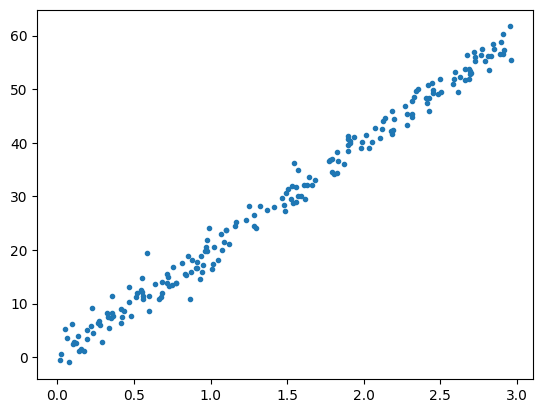

In [3]:
plt.plot(xy[:,0], xy[:,1], '.')

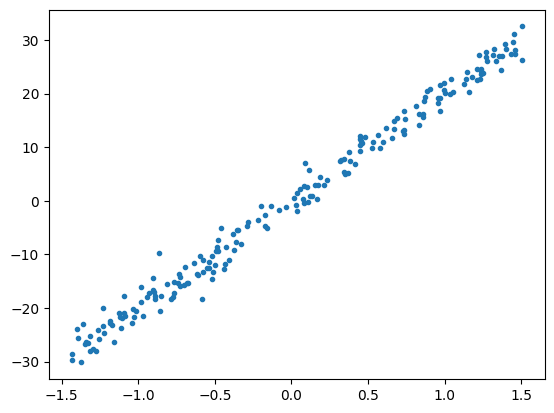

In [4]:
xy_centrado = xy - np.mean(xy, axis = 0)
plt.plot(xy_centrado[:,0], xy_centrado[:,1], '.')

[[-0.9987754  -0.04947417]
 [ 0.04947417 -0.9987754 ]]


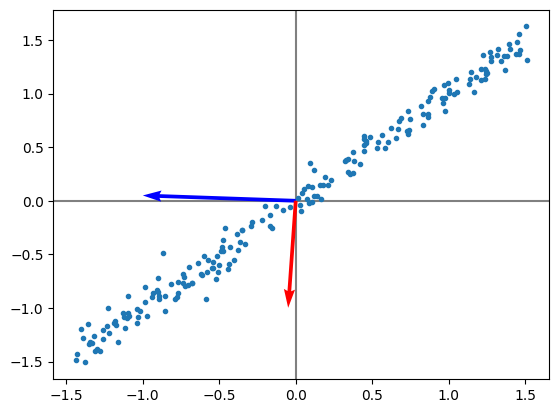

In [5]:
autovalores, autovectores = np.linalg.eig(xy_centrado.T.dot(xy_centrado))
print(autovectores)

graficarVectores(autovectores.T, ['blue', 'red'])

plt.plot(xy_centrado[:, 0], xy_centrado[:, 1]/20, '.')


[1.85050946e+00 6.28759594e+04]


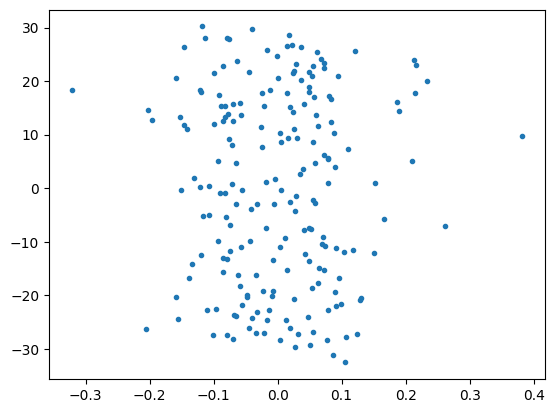

In [6]:
print(autovalores)

xy_nuevo = autovectores.T.dot(xy_centrado.T)
plt.plot(xy_nuevo[0, :], xy_nuevo[1, :], '.')

In [10]:
#PREPARAR IMAGENES PARA PCA

im= imageio.imread("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Algebra_lineal_para_Machine_Learning/imagenes/s3/3.pgm")
im= im.astype(np.uint8) #Definir el numero que la imagen tiene dentro
print(im)

[[101 106 102 ... 108 107 108]
 [101 104 102 ... 106 108 105]
 [ 99 104 102 ... 108 106 111]
 ...
 [ 64  69  75 ...  42  48  48]
 [ 74  81  85 ...  46  48  44]
 [ 77  83  84 ...  46  50  45]]


C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_2808\3660177259.py:3: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  im= imageio.imread("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Algebra_lineal_para_Machine_Learning/imagenes/s3/3.pgm")


In [12]:
print("Max original", end= " ")
print(np.amax(im))
print("Min original", end= " ")
print(np.amin(im))

Max original 204
Min original 10


In [13]:
im_original= im
im= im/255 #Normalizar por 255 porque es el numero mas alto que puede haber

print("Max original", end= " ")
print(np.amax(im))
print("Min original", end= " ")
print(np.amin(im))

Max original 0.8
Min original 0.0392156862745098


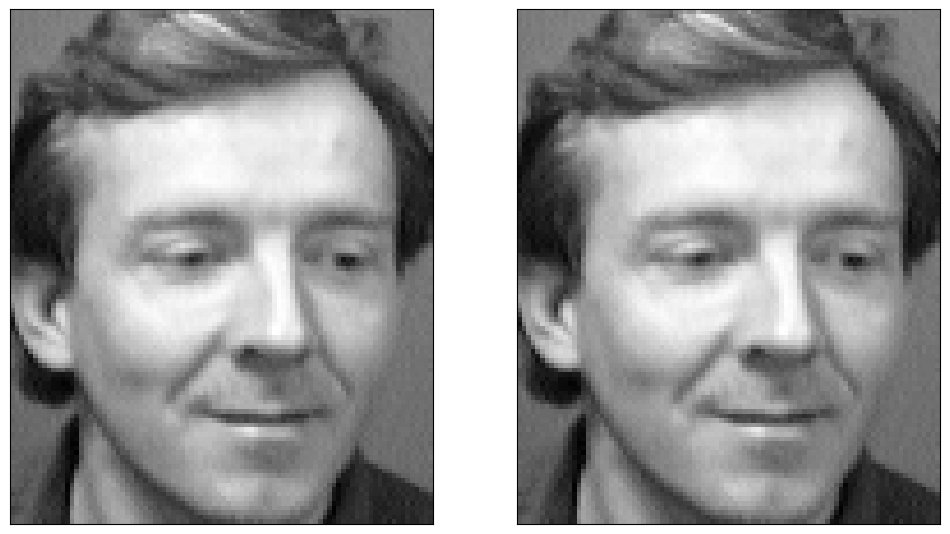

In [14]:
fig, ax= plt.subplots(1,2, figsize= (12,12),
subplot_kw= {"xticks": [], "yticks": []})

ax[0].imshow(im_original, cmap= "gray")
ax[1].imshow(im, cmap= "gray")

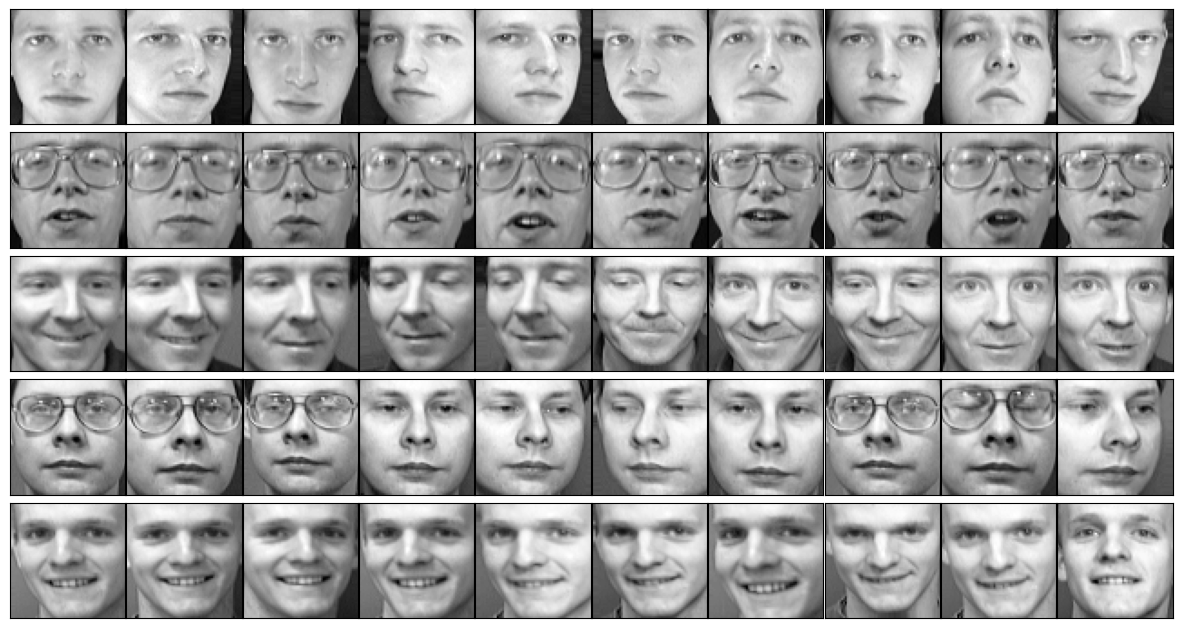

In [2]:
data = sklearn.datasets.fetch_olivetti_faces()
caras = pd.DataFrame([])

for i in range(50):
  cara = data.data[i].reshape(64,64)
  caraa = pd.Series(cara.flatten(), name=i)
  caras = pd.concat([caras, caraa], axis=1)

caras = caras.T

fig, axes = plt.subplots(5,10, figsize=(15,8),
                         subplot_kw = {'xticks': [], 'yticks': [],},
                         gridspec_kw = dict(hspace = 0.01, wspace=0.01))

for i, ax in enumerate(axes.flat):
  ax.imshow(caras.iloc[i].values.reshape(64,64),cmap='gray')


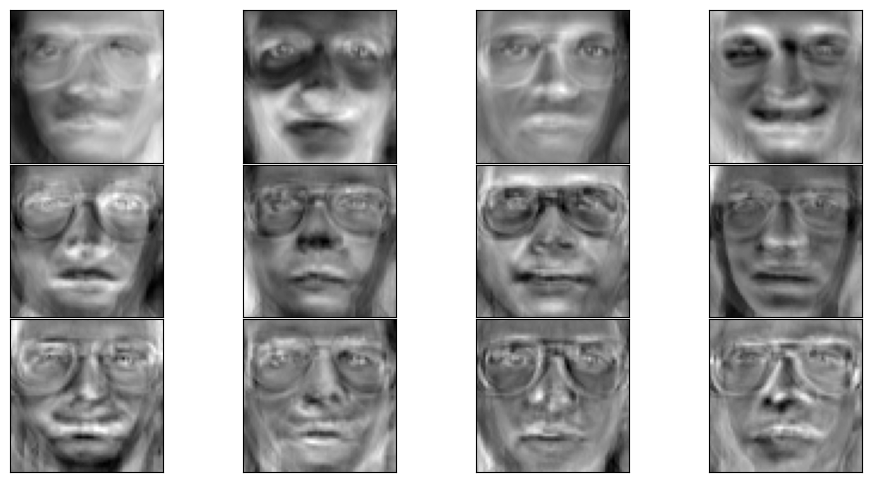

In [24]:
caras_pca= PCA(n_components= 0.8) #El numero de componentes sea el necesario para quedarse con el 50% de la variacion de los datos
caras_pca.fit(caras)

filas= 3
columnas = caras_pca.n_components_ // filas

fig, axes = plt.subplots(filas, columnas, figsize=(12,6),
                         subplot_kw = {'xticks': [], 'yticks': [],},
                         gridspec_kw = dict(hspace = 0.01, wspace=0.01))

#for i, ax in enumerate(axes.flat):
#   ax.imshow(caras_pca.components_[i].iloc[i].reshape(112,92), cmap="gray")

for i, ax in enumerate(axes.flat):
    ax.imshow(caras_pca.components_[i].reshape(64, 64), cmap="gray")

In [25]:
print(caras_pca.n_components_)

12


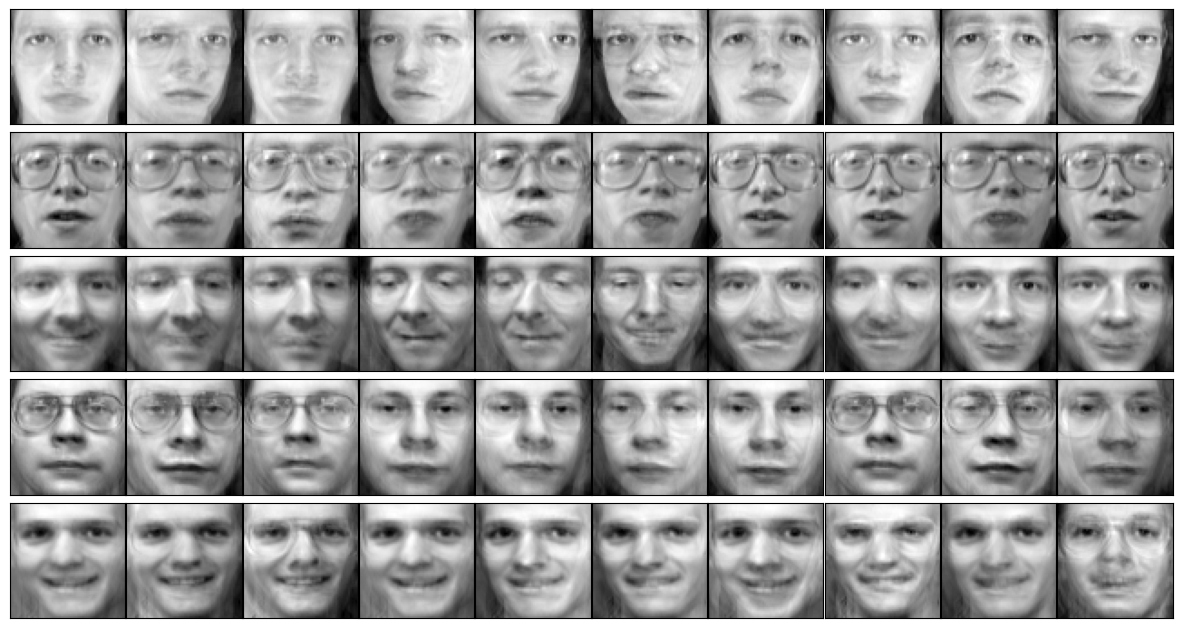

In [26]:
componentes= caras_pca.transform(caras)
proyeccion= caras_pca.inverse_transform(componentes)

fig, axes = plt.subplots(5,10, figsize=(15,8),
                         subplot_kw = {'xticks': [], 'yticks': [],},
                         gridspec_kw = dict(hspace = 0.01, wspace=0.01))

for i, ax in enumerate(axes.flat):
    ax.imshow(proyeccion[i].reshape(64, 64), cmap="gray")